# Taxi-v3: Q-Learning vs SARSA and Exploration Schedules

Curated from completed Artificial Intelligence coursework at Sharif University of Technology.
Repository owner: Amirhossein Hashemi Shahroodi (`amirshs84`).
Course-provided prompts, data and scaffolding are not claimed as original work; see `../../ATTRIBUTION.md`.
Run cells from top to bottom in this notebook’s directory. See the root README for scope, dependencies and limitations.



## Project Description

In this homework, we implement and compare two classical reinforcement learning algorithms:

1. **Q-Learning**
2. **SARSA**

We evaluate these algorithms on the **Taxi-v3** environment from the Gymnasium library.

Additionally, we compare two different action-selection strategies:

- **Fixed Epsilon-Greedy**
- **Decaying Epsilon-Greedy**

---

## Objective of Taxi

The goal of the Taxi problem is to pick up a passenger at one location and drop them off at their destination in the shortest time possible. The agent must navigate a 5×5 grid, avoid illegal pickups and dropoffs, and plan an efficient route.

## Algorithms Overview

### Q-Learning

Q-Learning is an **off-policy** temporal difference learning algorithm.
It updates the Q-values using the maximum estimated future reward.

Update equation:

$$
Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma \max_{a'} Q(s',a') - Q(s,a)]
$$

---

### SARSA

SARSA is an **on-policy** temporal difference learning algorithm.
It updates the Q-values using the action actually selected by the current policy.

Update equation:

$$
Q(s,a) \leftarrow Q(s,a) + \alpha [r + \gamma Q(s',a') - Q(s,a)]
$$

---

## Exploration Strategies

### Fixed Epsilon-Greedy

- With probability $\epsilon$, choose a random action.
- Otherwise, choose the best known action.

### Decaying Epsilon-Greedy

- Start with a high exploration rate.
- Gradually reduce epsilon during training.
- Helps the agent explore early and exploit later.

---

## Goals of This Homework

- Implement Q-Learning
- Implement SARSA
- Implement epsilon-greedy exploration
- Implement decaying epsilon-greedy exploration
- Train agents on Taxi-v3
- Compare learning performance using plots and evaluation metrics

In [1]:
import math
import random
from dataclasses import dataclass

import gymnasium as gym
import matplotlib.pyplot as plt
import time
import numpy as np
import pandas as pd
from tqdm.auto import trange

plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.grid"] = True

SEED = 42

## Environment Overview

Taxi-v3 has:
- observation space: 500 discrete states (no discretization needed)
- action space: 6 discrete actions (south, north, east, west, pickup, dropoff)
- reward: -1 per step, +20 for successful dropoff, -10 for illegal pickup/dropoff
- episode limit: 200 steps


In [2]:
env = gym.make('Taxi-v3')

print(f"State space: {env.observation_space.n}")
print(f"Action space: {env.action_space.n}")  
print("Observation space:", env.observation_space)
print("Action space:", env.action_space)
obs, info = env.reset()
print("Initial observation:", obs)
env.close()

State space: 500
Action space: 6
Observation space: Discrete(500)
Action space: Discrete(6)
Initial observation: 147


## Action selection

Two action-selection rules are used:

- **epsilon-greedy**: explore with a fixed probability `epsilon`
- **decaying epsilon-greedy**: start exploratory, then reduce `epsilon` over episodes

In [3]:
def epsilon_greedy_action(q_table, state, epsilon, n_actions, rng):
    if rng.random() < epsilon:
        return int(rng.integers(n_actions))
    return int(np.argmax(q_table[state]))


def epsilon_schedule_fixed(episode, epsilon_start=0.1, epsilon_min=0.1, decay_rate=1.0):
    return epsilon_start


def epsilon_schedule_decay(episode, epsilon_start=1.0, epsilon_min=0.01, decay_rate=0.995):
    epsilon = epsilon_start * (decay_rate ** episode)
    return max(epsilon, epsilon_min)


## Training functions

The notebook trains four combinations:

1. Q-learning + fixed epsilon-greedy
2. Q-learning + decaying epsilon-greedy
3. SARSA + fixed epsilon-greedy
4. SARSA + decaying epsilon-greedy

For each run, it records episode return and episode length, then evaluates the learned policy without exploration.  
Q-learning is off-policy and updates toward the greedy next action. SARSA is on-policy and updates using the next action actually chosen by the behavior policy.

In [4]:
@dataclass
class TrainResult:
    q_table: np.ndarray
    episode_returns: np.ndarray
    episode_lengths: np.ndarray
    epsilons: np.ndarray

def train_q_learning(
    env_id="Taxi-v3",
    episodes=5000,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_min=0.01,
    decay_rate=0.995,
    schedule="decay",
    verbose=True,
):
    env = gym.make(env_id)
    rng = np.random.default_rng()

    n_states = env.observation_space.n
    n_actions = env.action_space.n

    q_table = np.zeros((n_states, n_actions))

    episode_returns = np.zeros(episodes)
    episode_lengths = np.zeros(episodes, dtype=np.int64)
    epsilons = np.zeros(episodes)

    schedule_fn = epsilon_schedule_fixed if schedule == "fixed" else epsilon_schedule_decay
    episode_iter = trange(episodes, desc=f"Q-learning ({schedule})") if verbose else range(episodes)

    for ep in episode_iter:
        state, _ = env.reset()

        epsilon = schedule_fn(ep, epsilon_start, epsilon_min, decay_rate)
        epsilons[ep] = epsilon

        done = False
        total_reward = 0.0
        t = 0

        while not done:
            action = epsilon_greedy_action(q_table, state, epsilon, n_actions, rng)

            next_state, reward, terminated, truncated, _ = env.step(action)

            done = terminated or truncated

            target = reward + gamma * np.max(q_table[next_state]) * (not terminated)

            q_table[state][action] += alpha * (target - q_table[state][action])

            state = next_state
            total_reward += reward
            t += 1

        episode_returns[ep] = total_reward
        episode_lengths[ep] = t

    env.close()
    return TrainResult(q_table, episode_returns, episode_lengths, epsilons)


def train_sarsa(
    env_id="Taxi-v3",
    episodes=5000,
    alpha=0.1,
    gamma=0.99,
    epsilon_start=1.0,
    epsilon_min=0.01,
    decay_rate=0.995,
    schedule="decay",
    verbose=True,
):
    env = gym.make(env_id)
    rng = np.random.default_rng()

    n_states = env.observation_space.n
    n_actions = env.action_space.n

    q_table = np.zeros((n_states, n_actions))

    episode_returns = np.zeros(episodes)
    episode_lengths = np.zeros(episodes, dtype=np.int64)
    epsilons = np.zeros(episodes)

    schedule_fn = epsilon_schedule_fixed if schedule == "fixed" else epsilon_schedule_decay
    episode_iter = trange(episodes, desc=f"SARSA ({schedule})") if verbose else range(episodes)

    for ep in episode_iter:
        state, _ = env.reset()

        epsilon = schedule_fn(ep, epsilon_start, epsilon_min, decay_rate)
        epsilons[ep] = epsilon

        action = epsilon_greedy_action(q_table, state, epsilon, n_actions, rng)

        done = False
        total_reward = 0.0
        t = 0

        while not done:
            next_state, reward, terminated, truncated, _ = env.step(action)

            next_action = epsilon_greedy_action(q_table, next_state, epsilon, n_actions, rng)

            done = terminated or truncated

            target = reward + gamma * q_table[next_state][next_action] * (not terminated)

            q_table[state][action] += alpha * (target - q_table[state][action])

            state = next_state
            action = next_action
            total_reward += reward
            t += 1

        episode_returns[ep] = total_reward
        episode_lengths[ep] = t

    env.close()
    return TrainResult(q_table, episode_returns, episode_lengths, epsilons)


## Evaluation

Evaluation uses a greedy policy (`epsilon = 0`) to measure how well the learned Q-table performs after training.

In [5]:
def evaluate_policy(q_table, episodes=20, seed=SEED, env_id="Taxi-v3"):
    env = gym.make(env_id)
    
    returns = []
    lengths = []
    successes = 0

    for ep in range(episodes):
        state, _ = env.reset(seed=seed + ep)
        done = False
        total_reward = 0.0
        t = 0

        while not done:
            action = int(np.argmax(q_table[state]))
            
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            t += 1
            done = terminated or truncated
            
            if terminated and reward == 20:
                successes += 1

        returns.append(total_reward)
        lengths.append(t)

    env.close()
    return {
        "avg_return": float(np.mean(returns)),
        "avg_length": float(np.mean(lengths)),
        "success_rate": float(successes / episodes),
        "returns": np.array(returns),
        "lengths": np.array(lengths),
    }


## Run the experiments

We run the training for different numbers of episodes: 500, 1000, 3000, and 5000. For each episode count, we train four agents combining algorithm (Q-Learning, SARSA) and action selection policy (Fixed ε-greedy, Decaying ε-greedy).

In [6]:
import os
from concurrent.futures import ProcessPoolExecutor, as_completed
from tqdm.auto import tqdm

ALPHA = 0.1
GAMMA = 0.99
EPISODES_LIST = [500, 1000, 3000, 5000]

AGENT_CONFIGS = {
    "q_fixed":     dict(algo="q",     schedule="fixed", epsilon_start=0.1, epsilon_min=0.1,  decay_rate=1.0),
    "q_decay":     dict(algo="q",     schedule="decay", epsilon_start=1.0, epsilon_min=0.01, decay_rate=0.995),
    "sarsa_fixed": dict(algo="sarsa", schedule="fixed", epsilon_start=0.1, epsilon_min=0.1,  decay_rate=1.0),
    "sarsa_decay": dict(algo="sarsa", schedule="decay", epsilon_start=1.0, epsilon_min=0.01, decay_rate=0.995),
}

def _run_single_training(job):
    episodes, name, cfg = job
    train_fn = train_q_learning if cfg["algo"] == "q" else train_sarsa
    result = train_fn(
        episodes=episodes,
        alpha=ALPHA,
        gamma=GAMMA,
        epsilon_start=cfg["epsilon_start"],
        epsilon_min=cfg["epsilon_min"],
        decay_rate=cfg["decay_rate"],
        schedule=cfg["schedule"],
        verbose=False,
    )
    return episodes, name, result

jobs = [(episodes, name, cfg) for episodes in EPISODES_LIST for name, cfg in AGENT_CONFIGS.items()]
results_by_episodes = {episodes: {} for episodes in EPISODES_LIST}

print(f"Training {len(jobs)} agents sequentially for notebook portability...")
for job in tqdm(jobs, desc="Training progress"):
    episodes, name, result = _run_single_training(job)
    results_by_episodes[episodes][name] = result

results_500 = results_by_episodes[500]
results_1000 = results_by_episodes[1000]
results_3000 = results_by_episodes[3000]
results_5000 = results_by_episodes[5000]

print("All agents trained and stored in memory!")


Training 16 agents sequentially for notebook portability...
Training progress: 100%|##########| 16/16 [00:18<00:00,  1.16s/it]
All agents trained and stored in memory!


## Performance Summary

Tables showing evaluation metrics for each agent at different training episode counts, followed by a combined summary of all results.

In [7]:
all_eval_rows = []

all_results = {
    "500": results_500,
    "1000": results_1000,
    "3000": results_3000,
    "5000": results_5000,
}

for episodes, results in all_results.items():
    eval_rows = []
    
    for name, res in results.items():
        metrics = evaluate_policy(res.q_table, episodes=20)
        eval_rows.append({
            "algorithm": name,
            "avg_eval_return": metrics["avg_return"],
            "avg_eval_length": metrics["avg_length"],
            "success_rate": metrics["success_rate"],
        })
        
        all_eval_rows.append({
            "episodes": episodes,
            "algorithm": name,
            "avg_eval_return": metrics["avg_return"],
            "avg_eval_length": metrics["avg_length"],
            "success_rate": metrics["success_rate"],
        })
    
    print(f"\n{'='*50}")
    print(f"Episodes: {episodes}")
    print(f"{'='*50}")
    summary_ep = pd.DataFrame(eval_rows).sort_values("avg_eval_return", ascending=False).reset_index(drop=True)
    print(summary_ep)

print(f"\n{'='*50}")
print("ALL RESULTS")
print(f"{'='*50}")
summary_df = pd.DataFrame(all_eval_rows).sort_values("avg_eval_return", ascending=False).reset_index(drop=True)
summary_df


Episodes: 500
     algorithm  avg_eval_return  avg_eval_length  success_rate
0      q_fixed          -189.40           190.45          0.05
1      q_decay          -200.00           200.00          0.00
2  sarsa_decay          -200.00           200.00          0.00
3  sarsa_fixed          -458.85           190.80          0.05

Episodes: 1000
     algorithm  avg_eval_return  avg_eval_length  success_rate
0      q_fixed          -116.25           124.65          0.40
1  sarsa_fixed          -137.60           143.90          0.30
2  sarsa_decay          -147.50           152.75          0.25
3      q_decay          -168.45           171.60          0.15

Episodes: 3000
     algorithm  avg_eval_return  avg_eval_length  success_rate
0  sarsa_decay             6.85            14.15          1.00
1      q_fixed            -3.30            23.25          0.95
2      q_decay            -3.40            23.35          0.95
3  sarsa_fixed           -23.85            41.70          0.85

Episode

## Training Curves

The plots below show the moving average of episode returns and lengths during training for each combination of algorithm and policy. Each plot corresponds to a different number of training episodes (500, 1000, 3000, 5000).

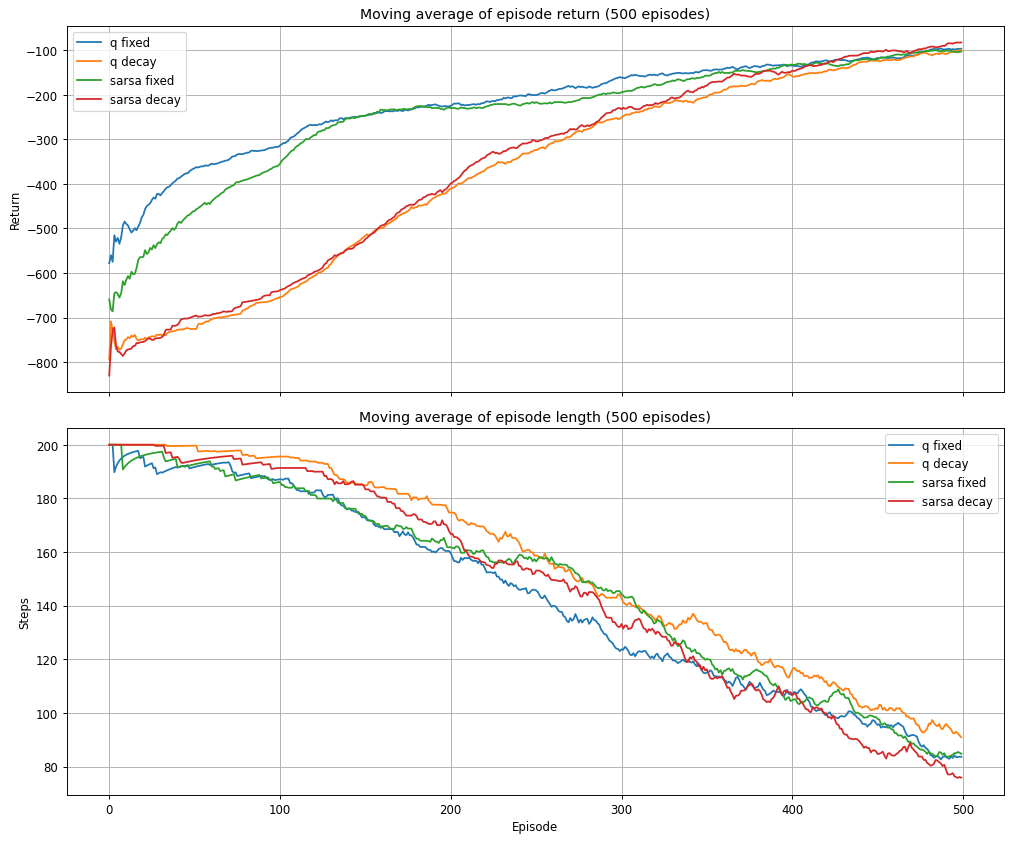

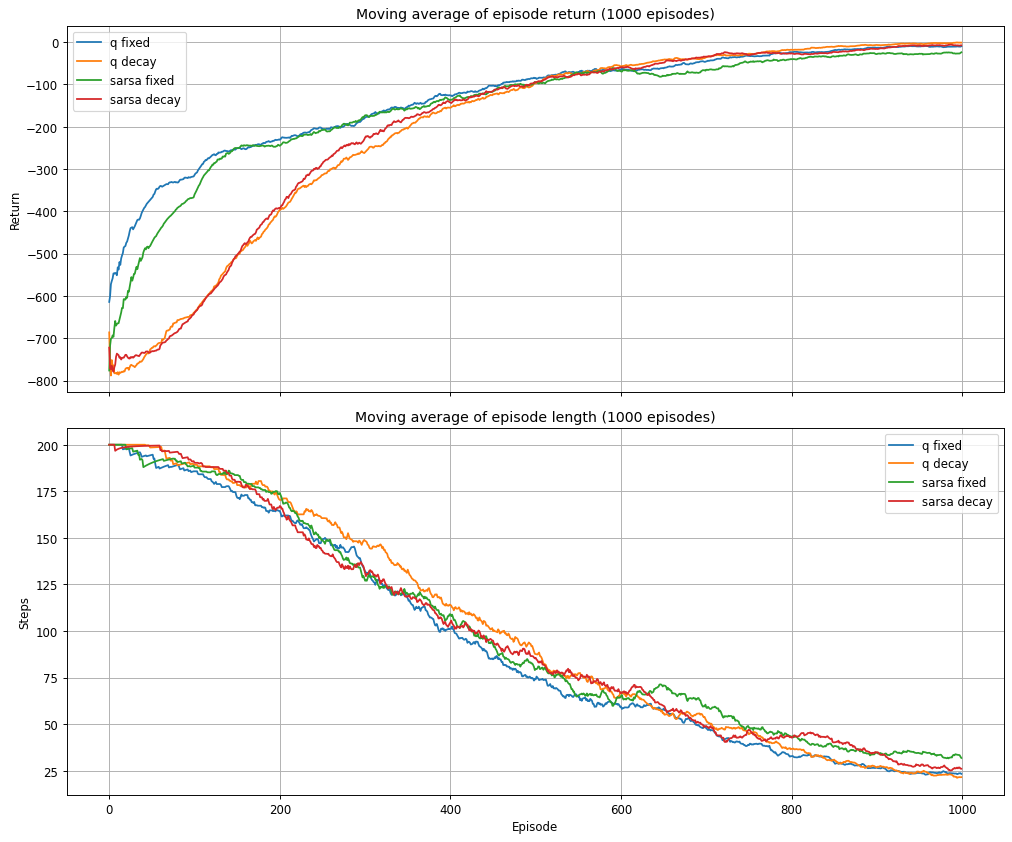

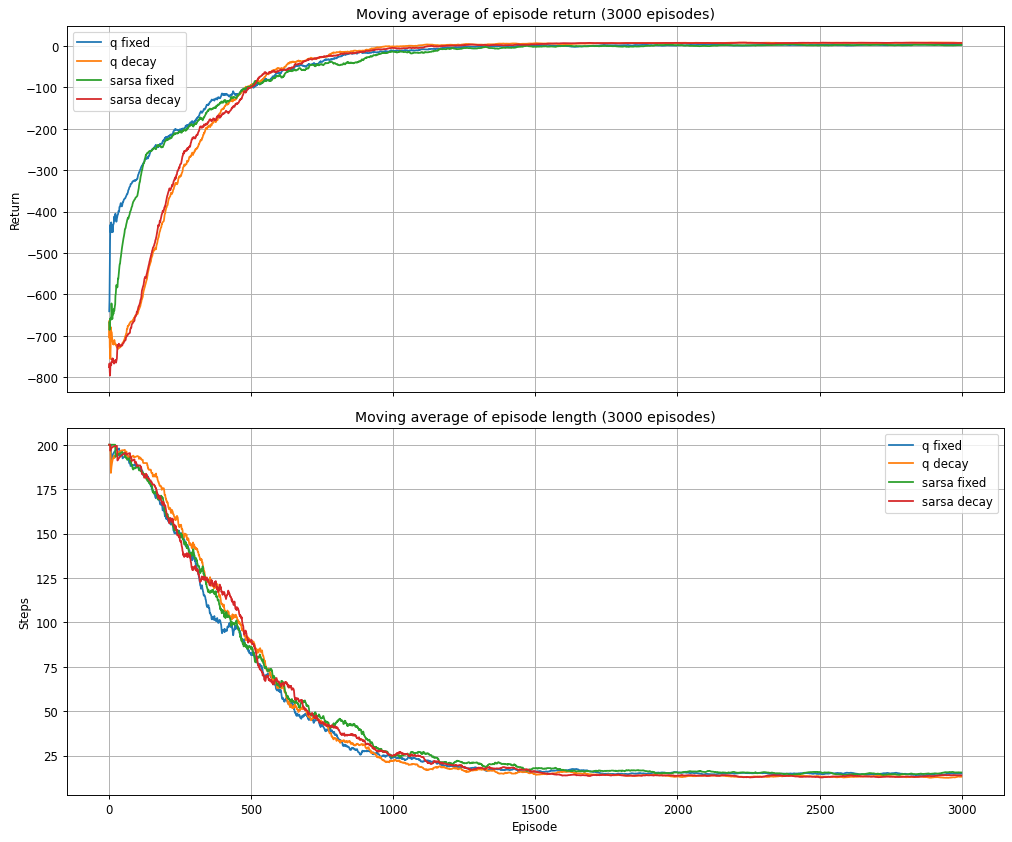

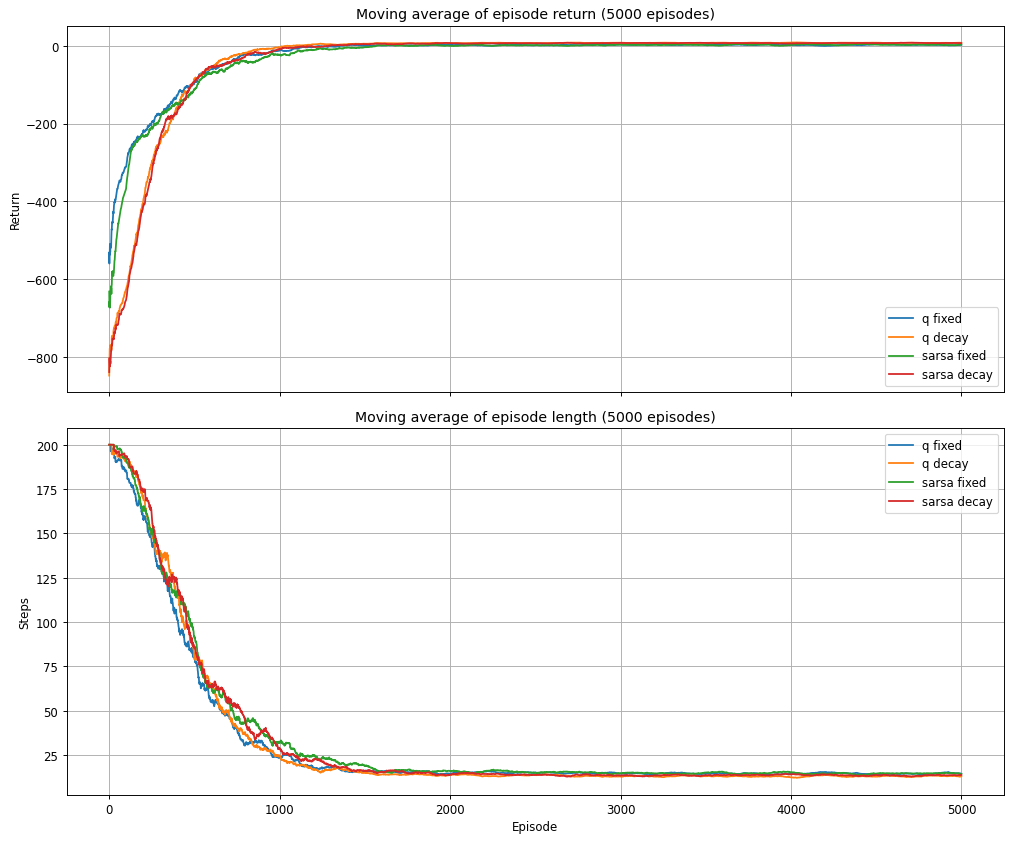

In [8]:
def moving_average(x, window=100):
    if len(x) < window:
        return np.array([])
    return pd.Series(x).rolling(window=window, min_periods=1).mean().values

for episodes, results in all_results.items():
    fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)
    
    for name, res in results.items():
        label = name.replace("_", " ")
        axes[0].plot(moving_average(res.episode_returns, 100), label=label)
        axes[1].plot(moving_average(res.episode_lengths, 100), label=label)
    
    axes[0].set_title(f"Moving average of episode return ({episodes} episodes)")
    axes[0].set_ylabel("Return")
    axes[0].legend()
    
    axes[1].set_title(f"Moving average of episode length ({episodes} episodes)")
    axes[1].set_xlabel("Episode")
    axes[1].set_ylabel("Steps")
    axes[1].legend()
    
    plt.tight_layout()
    plt.show()

## Evaluation Results

Bar charts comparing agent performance after training for different numbers of episodes.

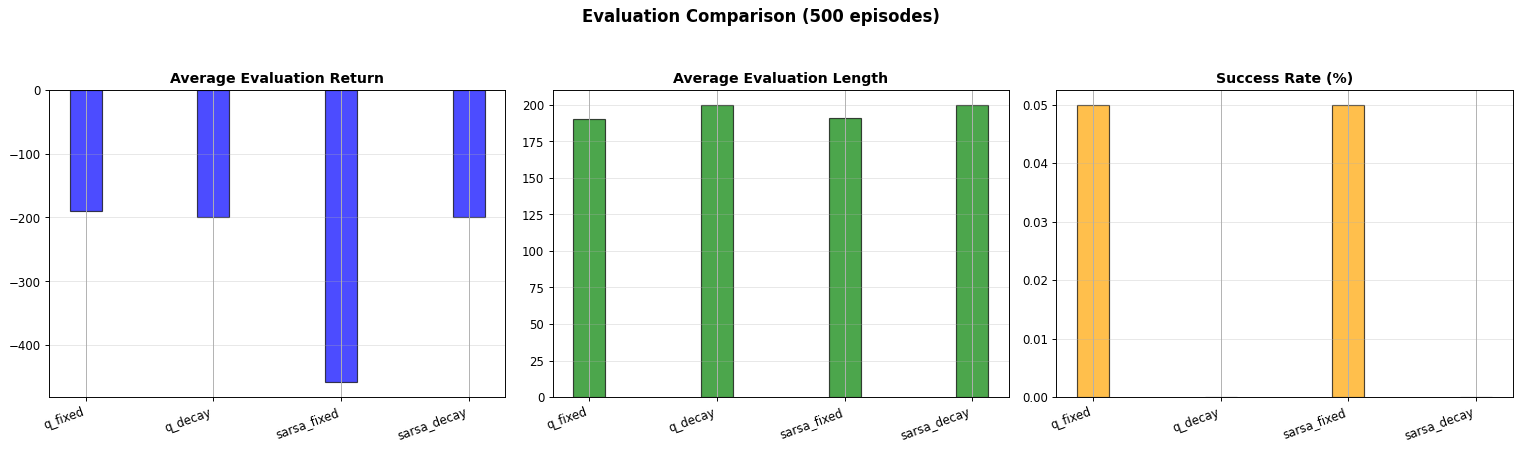

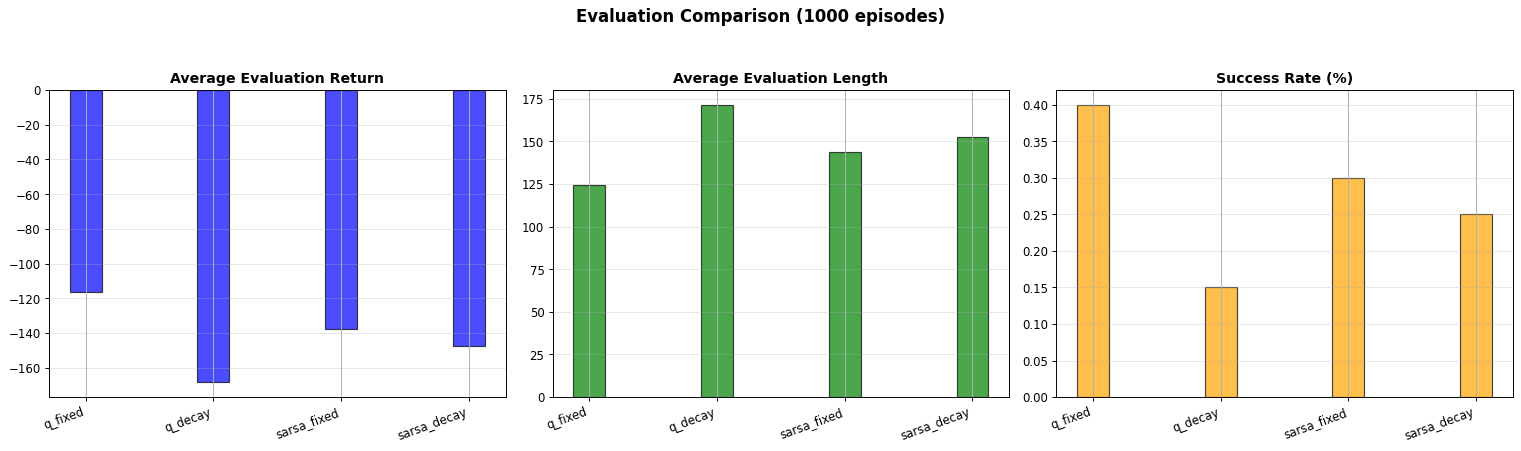

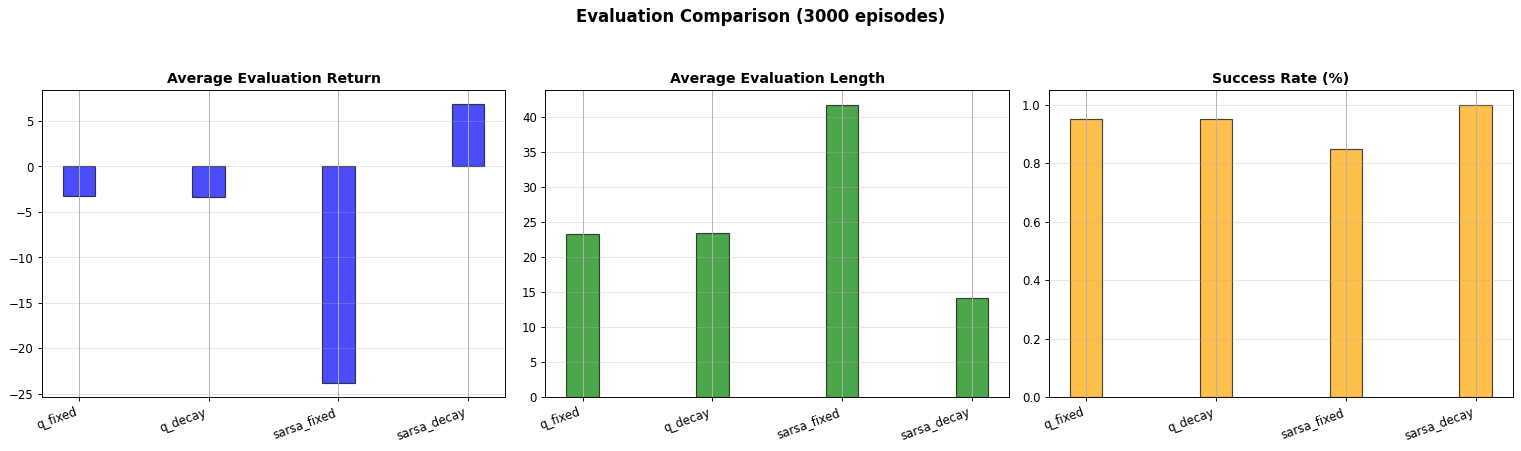

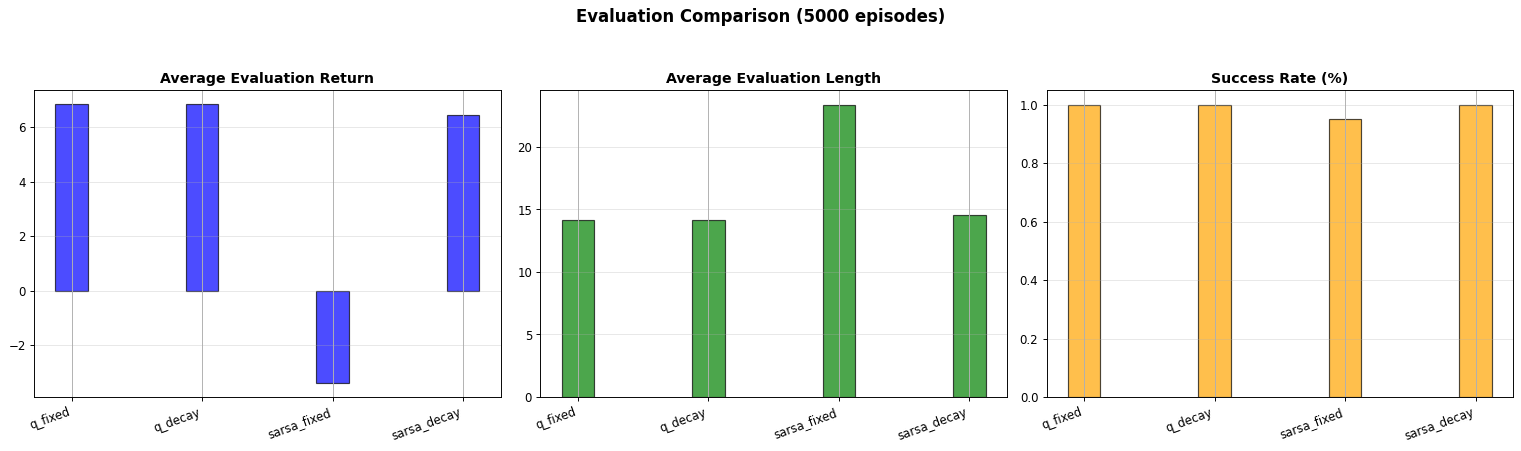

In [9]:
for episodes, results in all_results.items():
    eval_rows = []
    for name, res in results.items():
        metrics = evaluate_policy(res.q_table, episodes=20)
        eval_rows.append({
            "setting": name,
            "avg_eval_return": metrics["avg_return"],
            "avg_eval_length": metrics["avg_length"],
            "success_rate": metrics["success_rate"],
        })
    
    summary_df = pd.DataFrame(eval_rows)
    
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    width = 0.25
    x = np.arange(len(summary_df))

    # Plot 1: Average Evaluation Return
    axes[0].bar(x, summary_df["avg_eval_return"], width, color='blue', alpha=0.7, edgecolor='black')
    axes[0].set_title("Average Evaluation Return", fontweight='bold')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(summary_df["setting"], rotation=20, ha="right")
    axes[0].grid(axis='y', alpha=0.3)

    # Plot 2: Average Evaluation Length
    axes[1].bar(x, summary_df["avg_eval_length"], width, color='green', alpha=0.7, edgecolor='black')
    axes[1].set_title("Average Evaluation Length", fontweight='bold')
    axes[1].set_xticks(x)
    axes[1].set_xticklabels(summary_df["setting"], rotation=20, ha="right")
    axes[1].grid(axis='y', alpha=0.3)

    # Plot 3: Success Rate
    axes[2].bar(x, summary_df["success_rate"], width, color='orange', alpha=0.7, edgecolor='black')
    axes[2].set_title("Success Rate (%)", fontweight='bold')
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(summary_df["setting"], rotation=20, ha="right")
    axes[2].grid(axis='y', alpha=0.3)

    plt.suptitle(f'Evaluation Comparison ({episodes} episodes)', fontsize=14, fontweight='bold', y=1.05)
    plt.tight_layout()
    plt.show()

## Agent Demonstration

Animations showing three trained agents solving the Taxi problem.

In [10]:
RUN_ANIMATIONS = False  # Requires pygame and FFmpeg
if RUN_ANIMATIONS:
    from matplotlib.animation import FuncAnimation
    from IPython.display import HTML
    
    def run_greedy_episode_animation(q_table, env_id="Taxi-v3"):
        """Run a greedy episode and create an animation for Taxi"""
        env = gym.make(env_id, render_mode='rgb_array')
        state, _ = env.reset(seed=SEED)
        done = False
        total_reward = 0.0
        steps = 0
        
        frames = []
        
        while not done:
            action = int(np.argmax(q_table[state]))
            state, reward, terminated, truncated, _ = env.step(action)
            total_reward += reward
            steps += 1
            done = terminated or truncated
            
            frame = env.render()
            frames.append(frame)
        
        env.close()
        
        # Create animation
        fig, ax = plt.subplots(figsize=(8, 6))
        ax.axis('off')
        
        def animate(i):
            ax.clear()
            ax.imshow(frames[i])
            ax.axis('off')
            
            status = ""
            if i == len(frames)-1 and total_reward > 0:
                status = "\n✅ Passenger delivered!"
            
            ax.set_title(f'Taxi - Step {i+1}/{steps}\n'
                        f'Total Reward: {total_reward}'
                        f'{status}', 
                        fontsize=12)
        
        anim = FuncAnimation(fig, animate, frames=len(frames), interval=200)
        plt.close()
        
        return anim, steps, total_reward
    
    # Show 3 examples: Good, Medium, Bad
    # Pick agents from results_500 (worst), results_1000 (medium), results_5000 (best)
    agents_to_show = {
        "5000 ep - q_decay": results_5000["q_decay"].q_table,
        "1000 ep - sarsa_decay": results_1000["sarsa_decay"].q_table,
        "500 ep - q_fixed": results_500["q_fixed"].q_table
    }
    
    for name, q_table in agents_to_show.items():
        print(f"\nAgent: {name}")
        anim, steps, total_reward = run_greedy_episode_animation(q_table)
        print(f"Steps: {steps}, Reward: {total_reward}")
        display(HTML(anim.to_html5_video()))
        time.sleep(1)


## Interpretation and limitations

Q-learning is off-policy; SARSA updates using the next action actually selected by its behavior policy. Compare their greedy evaluation returns, episode lengths and success rates separately from exploratory training returns.

The supplied outputs at 5,000 episodes show 100% success for both Q-learning configurations and SARSA with decay, but 95% for fixed-epsilon SARSA over only 20 evaluation episodes. This does not establish general superiority or convergence. Training RNGs and environment resets were not seeded in the original submission; evaluation uses fixed reset seeds. Reruns will differ. Multiple training seeds and uncertainty intervals are needed for stronger conclusions.
